# E2 - MobileNetV3-Small + LSTM Compact CRNN Baseline

This notebook implements **E2**, the compact temporal baseline in the BTP experiment plan.

E2 keeps the ASVspoof E1 dataset partitions, labels, metrics, audio representation and training protocol fixed. The detector head is changed to:

**80-bin log-Mel → MobileNetV3-Small feature extractor → frequency pooling → temporal sequence → 1-layer LSTM → classifier**

The implementation uses a faster batched input pipeline: audio loading, resampling and crop/padding remain in DataLoader workers, while STFT, Mel filtering and log compression are performed in batches on the GPU. This changes the implementation path, not the E2 research variable.

The purpose of E2 is to answer:

> **Does temporal modeling help?**

The temporal axis is therefore preserved after the MobileNet feature extractor and modeled with a lightweight LSTM.

## Before running the notebook

1. Keep the frozen ASVspoof train/dev/eval manifests unchanged.
2. Run E2 after E1 so the E1 result remains available for direct comparison.
3. Keep `TRAIN_FRACTION`, `DEV_FRACTION` and `EVAL_FRACTION` as `None` for the actual experiment.
4. This notebook does **not** add codec simulation, environmental noise, robustness consistency loss, pruning, quantization or edge benchmarking.
5. cuDNN settings are explicitly `deterministic=True` and `benchmark=False`.
6. The faster pipeline does **not** call `torch._removed_deterministic_algorithms(...)`.

# 1. Environment and project paths

This section imports the libraries used by the experiment and defines the paths to the project outputs.

The notebook assumes it is being run from the `notebooks/` directory. Therefore, the project root is resolved as the parent directory of the notebook location.

All experiment outputs are kept separate from the raw dataset so that the original ASVspoof files remain untouched.

## NOTE: still some minor issues to fix and rerun, mainly to ensure reproducibilty


In [2]:
# 1. Imports and project paths

from pathlib import Path
import json
import math
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
from tqdm.auto import tqdm

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
from torchvision.models import mobilenet_v3_small

warnings.filterwarnings("ignore")

# The notebook is stored in project_root/notebooks/
PROJECT_ROOT=Path("..").resolve()

DATA_ROOT=PROJECT_ROOT/"data"
MANIFEST_DIR=DATA_ROOT/"manifests"/"ASVSpoof"

TRAIN_MANIFEST=MANIFEST_DIR/"train_manifest.csv"
DEV_MANIFEST=MANIFEST_DIR/"dev_manifest.csv"
EVAL_MANIFEST=MANIFEST_DIR/"eval_manifest.csv"

CHECKPOINT_DIR=PROJECT_ROOT/"checkpoints"/"ASV_E2_LSTM"
EXPERIMENT_DIR=PROJECT_ROOT/"experiments"/"baselines"/"ASV_E2_LSTM"
RESULT_TABLE_DIR=PROJECT_ROOT/"results"/"tables"/"ASV_E2_LSTM"
RESULT_FIGURE_DIR=PROJECT_ROOT/"results"/"figures"/"ASV_E2_LSTM"
RESULT_LOG_DIR=PROJECT_ROOT/"results"/"logs"/"ASV_E2_LSTM"

for directory in [
    CHECKPOINT_DIR,
    EXPERIMENT_DIR,
    RESULT_TABLE_DIR,
    RESULT_FIGURE_DIR,
    RESULT_LOG_DIR
]:
    directory.mkdir(parents=True,exist_ok=True)

print("Project root:",PROJECT_ROOT)
print("Manifest directory:",MANIFEST_DIR)


Project root: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification
Manifest directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof


### Output layout

This LSTM baseline keeps its artifacts separate from E1 and E2-GRU:

```text
checkpoints/E2_LSTM/
experiments/baselines/E2_LSTM/
results/tables/E2_LSTM/
results/figures/E2_LSTM/
results/logs/E2_LSTM/
```

The ASVspoof manifests are read from `data/manifests/ASVSpoof/`.


# 2. Verify the prepared dataset

The preprocessing script creates three reproducible manifests:

- `train_manifest.csv`
- `dev_manifest.csv`
- `eval_manifest.csv`

We first check that these files exist before loading any data.

If the train or development manifest is missing, the notebook stops rather than silently creating a new split.


In [3]:
# 2. Check the generated manifests before training

required_files=[
    TRAIN_MANIFEST,
    DEV_MANIFEST,
    EVAL_MANIFEST
]

for path in required_files:
    status="OK" if path.exists() else "MISSING"
    print(f"{status:<8} {path}")

if not TRAIN_MANIFEST.exists() or not DEV_MANIFEST.exists():
    raise FileNotFoundError(
        "Train/dev manifests were not found. "
        "Run prepare_asvspoof_v1.py first."
    )


OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/train_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/dev_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/eval_manifest.csv


# 3. Reproducibility and experiment configuration

E2 keeps the original 16 kHz, 4-second, 80-bin log-Mel frontend and changes only the detector head scientifically. The implementation is optimized by batching feature extraction on the GPU.

The CUDA run uses:

- fixed random seeds
- `torch.backends.cudnn.deterministic=True`
- `torch.backends.cudnn.benchmark=False`
- multiple DataLoader workers with pinned memory and prefetching


In [4]:
# 3. Reproducibility and training configuration

SEED=42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def seed_worker(worker_id):
    worker_seed=torch.initial_seed()%2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

seed_everything(SEED)

DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type=="cuda":
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
    print("Device:",torch.cuda.get_device_name(0))
    print("cuDNN deterministic:",torch.backends.cudnn.deterministic)
    print("cuDNN benchmark:",torch.backends.cudnn.benchmark)
else:
    print("Device: CPU")

EXPERIMENT_VERSION="v1.0"
INPUT_PREPROCESSING_VERSION="v1.0"

BATCH_SIZE=32
EPOCHS=20
LEARNING_RATE=1e-3
WEIGHT_DECAY=1e-4
PATIENCE=5

NUM_WORKERS=4
PREFETCH_FACTOR=2

SAMPLE_RATE=16000
SEGMENT_SECONDS=4
NUM_SAMPLES=SAMPLE_RATE*SEGMENT_SECONDS

N_FFT=1024
WIN_LENGTH=400
HOP_LENGTH=160
N_MELS=80
LOG_EPS=1e-10

TRAIN_FRACTION=None
DEV_FRACTION=None
EVAL_FRACTION=None
STATS_MAX_FILES=None

print("Experiment version:",EXPERIMENT_VERSION)
print("Input preprocessing version:",INPUT_PREPROCESSING_VERSION)
print("Seed:",SEED)
print("Batch size:",BATCH_SIZE)
print("Epochs:",EPOCHS)
print("DataLoader workers:",NUM_WORKERS)
print("Prefetch factor:",PREFETCH_FACTOR)
print("Device:",DEVICE)

Device: NVIDIA GeForce RTX 3060 Laptop GPU
cuDNN deterministic: True
cuDNN benchmark: False
Experiment version: v1.0
Input preprocessing version: v1.0
Seed: 42
Batch size: 32
Epochs: 20
DataLoader workers: 4
Prefetch factor: 2
Device: cuda


# 4. Load the reproducible manifests

The manifests contain the file paths and labels prepared by `prepare_asvspoof_v1.py`.

We use the official ASVspoof train/dev/eval partitions rather than creating a random split inside the model notebook.

This is important because changing the split here would make E1 difficult to compare with later baseline experiments.


In [5]:
# 4. Load the reproducible manifests

train_df=pd.read_csv(TRAIN_MANIFEST)
dev_df=pd.read_csv(DEV_MANIFEST)

if EVAL_MANIFEST.exists():
    eval_df=pd.read_csv(EVAL_MANIFEST)
else:
    eval_df=pd.DataFrame()

print("Train:",len(train_df))
print("Dev:",len(dev_df))
print("Eval:",len(eval_df))
print("\nTrain columns:")
print(train_df.columns.tolist())
print("\nFirst training entries:")
display(train_df.head())


Train: 25380
Dev: 24844
Eval: 71237

Train columns:
['file_id', 'audio_path', 'speaker_id', 'system_id', 'key', 'label', 'split']

First training entries:


,file_id,audio_path,speaker_id,system_id,key,label,split
0,LA_T_1138215,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
1,LA_T_1271820,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
2,LA_T_1272637,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
3,LA_T_1276960,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
4,LA_T_1341447,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train


## Dataset integrity checks

Before training, we check whether the paths recorded in the manifests actually point to audio files.

A missing file should be investigated before the final experiment rather than silently skipped.


In [6]:
# 5. Verify that manifest paths point to existing files

def check_audio_files(df,project_root):
    if len(df)==0:
        return 0

    return sum(
        not (project_root/Path(path)).exists()
        for path in df["audio_path"]
    )

for name,df in [
    ("train",train_df),
    ("dev",dev_df),
    ("eval",eval_df)
]:
    if len(df)==0:
        continue

    missing=check_audio_files(df,PROJECT_ROOT)
    print(f"{name:<8}: {missing} missing audio files")

    if missing>0:
        print(f"WARNING: {name} contains missing files.")


train   : 0 missing audio files
dev     : 0 missing audio files
eval    : 0 missing audio files


## Class and speaker distribution

The class distribution is inspected before training because ASVspoof contains both bonafide and spoofed examples and the distribution is not necessarily balanced.

We also inspect speaker IDs. This is an audit only; the notebook does not modify the official partitions.


In [7]:
# 6. Inspect class and identity information from the manifests

def show_split_summary(df,name):
    print(f"\n{name.upper()}")
    print("-"*50)
    print("Files:",len(df))

    if "key" in df.columns:
        print("\nClass counts:")
        print(df["key"].value_counts(dropna=False))

    if "speaker_id" in df.columns:
        print("Speakers:",df["speaker_id"].nunique())

    if "system_id" in df.columns:
        print("System IDs:",df["system_id"].nunique())

show_split_summary(train_df,"train")
show_split_summary(dev_df,"dev")

if len(eval_df):
    show_split_summary(eval_df,"eval")

train_speakers=set(train_df["speaker_id"])
dev_speakers=set(dev_df["speaker_id"])

print("\nTrain/dev speaker overlap:",len(train_speakers&dev_speakers))



TRAIN
--------------------------------------------------
Files: 25380

Class counts:
key
spoof       22800
bonafide     2580
Name: count, dtype: int64
Speakers: 20
System IDs: 7

DEV
--------------------------------------------------
Files: 24844

Class counts:
key
spoof       22296
bonafide     2548
Name: count, dtype: int64
Speakers: 20
System IDs: 7

EVAL
--------------------------------------------------
Files: 71237

Class counts:
key
spoof       63882
bonafide     7355
Name: count, dtype: int64
Speakers: 67
System IDs: 14

Train/dev speaker overlap: 0


# 5. E2 input preprocessing

E2 deliberately uses the **same ASV E1 audio frontend**:

```text
FLAC → Mono → 16 kHz → fixed 4 s crop / zero-padding
     → STFT → 80-bin Mel → log power
     → training-set normalization → 1-channel tensor
```

The important implementation change is that the final STFT/Mel/log computation is performed **after batching on the GPU**, rather than inside `Dataset.__getitem__()` with Librosa.

In [8]:
# 7. Audio loading and batched GPU log-Mel conversion

def load_audio(path,target_sr=SAMPLE_RATE):
    waveform,sr=sf.read(path,dtype="float32")

    if waveform.ndim>1:
        waveform=waveform.mean(axis=1)

    if sr!=target_sr:
        waveform=librosa.resample(
            waveform,
            orig_sr=sr,
            target_sr=target_sr
        )

    waveform=waveform.astype(np.float32)
    waveform=np.nan_to_num(
        waveform,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return waveform


def fixed_length_audio(waveform,training=False):
    if len(waveform)>=NUM_SAMPLES:
        if training:
            start=np.random.randint(
                0,
                len(waveform)-NUM_SAMPLES+1
            )
        else:
            start=(len(waveform)-NUM_SAMPLES)//2

        waveform=waveform[
            start:start+NUM_SAMPLES
        ]

    else:
        padded=np.zeros(
            NUM_SAMPLES,
            dtype=np.float32
        )
        padded[:len(waveform)]=waveform
        waveform=padded

    return waveform


class GPULogMel(nn.Module):

    def __init__(
        self,
        sample_rate,
        n_fft,
        win_length,
        hop_length,
        n_mels,
        log_eps=1e-10
    ):
        super().__init__()

        self.n_fft=n_fft
        self.win_length=win_length
        self.hop_length=hop_length
        self.log_eps=log_eps

        window=torch.hann_window(
            win_length,
            periodic=True,
            dtype=torch.float32
        )

        mel_filter=librosa.filters.mel(
            sr=sample_rate,
            n_fft=n_fft,
            n_mels=n_mels,
            fmin=0.0,
            fmax=sample_rate/2.0,
            htk=False,
            norm="slaney"
        )

        self.register_buffer(
            "window",
            window
        )
        self.register_buffer(
            "mel_filter",
            torch.tensor(
                mel_filter,
                dtype=torch.float32
            )
        )

    def forward(self,waveforms):
        stft=torch.stft(
            waveforms.float(),
            n_fft=self.n_fft,
            hop_length=self.hop_length,
            win_length=self.win_length,
            window=self.window,
            center=True,
            pad_mode="constant",
            return_complex=True
        )

        power=stft.abs().pow(2.0)

        mel=torch.matmul(
            self.mel_filter,
            power
        )

        log_mel=torch.log(
            torch.clamp(
                mel,
                min=self.log_eps
            )
        )

        return log_mel


gpu_logmel=GPULogMel(
    SAMPLE_RATE,
    N_FFT,
    WIN_LENGTH,
    HOP_LENGTH,
    N_MELS,
    LOG_EPS
).to(DEVICE)


def cpu_logmel_for_visualization(waveform):
    mel=librosa.feature.melspectrogram(
        y=waveform,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        win_length=WIN_LENGTH,
        window="hann",
        n_mels=N_MELS,
        power=2.0
    )

    return np.log(
        np.maximum(mel,LOG_EPS)
    ).astype(np.float32)

## Visual sanity check

Before training, we display one example log-Mel spectrogram.

This is mainly a pipeline check: we want to confirm that audio loading, resampling, cropping and Mel extraction are producing a valid two-dimensional time-frequency representation.


Waveform shape: (64000,)
Log-Mel shape: (80, 401)


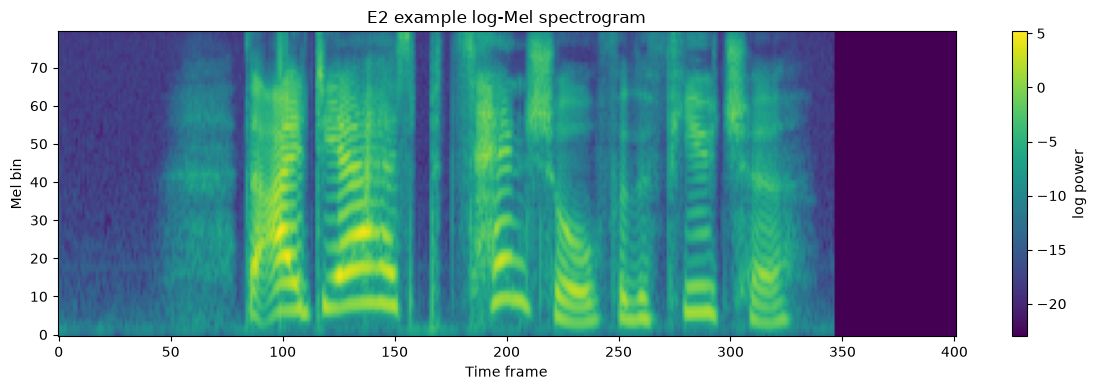

In [9]:
# 8. Visual sanity check for the input representation

sample_path=PROJECT_ROOT/Path(
    train_df.iloc[0]["audio_path"]
)

sample_wave=load_audio(sample_path)
sample_wave=fixed_length_audio(
    sample_wave,
    training=False
)

sample_logmel=cpu_logmel_for_visualization(sample_wave)

print("Waveform shape:",sample_wave.shape)
print("Log-Mel shape:",sample_logmel.shape)

plt.figure(figsize=(12,4))
plt.imshow(
    sample_logmel,
    origin="lower",
    aspect="auto"
)
plt.title("E2 example log-Mel spectrogram")
plt.xlabel("Time frame")
plt.ylabel("Mel bin")
plt.colorbar(label="log power")
plt.tight_layout()
plt.show()

# 6. Optional smoke-test subsets

The following settings allow a small subset of the data to be used while debugging the pipeline.

For example:

```python
TRAIN_FRACTION=0.02
DEV_FRACTION=0.02
```

can be used to verify that the complete training loop works.

For the **actual E1 experiment**, keep all three fraction variables as `None`.

This prevents a debugging run from accidentally being treated as the final baseline.


In [10]:
# 9. Optional smoke-test subsets
# Keep these as None for the final experiment (In code cell 3)

def take_fraction(df,fraction,seed=42):
    if fraction is None or fraction>=1.0:
        return df.copy()

    if fraction<=0:
        raise ValueError("Fraction must be greater than 0.")

    pieces=[]

    for label,group in df.groupby("label"):
        n=max(1,int(len(group)*fraction))
        pieces.append(group.sample(n=n,random_state=seed))

    return pd.concat(pieces).sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)


train_run_df=take_fraction(train_df,TRAIN_FRACTION,SEED)
dev_run_df=take_fraction(dev_df,DEV_FRACTION,SEED)

if len(eval_df):
    eval_run_df=take_fraction(eval_df,EVAL_FRACTION,SEED)
else:
    eval_run_df=eval_df

print("Train:",len(train_run_df))
print("Dev:",len(dev_run_df))
print("Eval:",len(eval_run_df))


Train: 25380
Dev: 24844
Eval: 71237


# 7. Training-set normalization statistics

The mean and standard deviation of the log-Mel representation are calculated using **only the training partition**.

Validation and evaluation data are not used to calculate these statistics.

Once calculated, the values are saved to:

```text
experiments/baselines/E1/logmel_stats.json
```

Future E1 runs can reuse the saved statistics instead of recalculating them, provided the preprocessing version and dataset preparation remain unchanged.


In [11]:
# 10. Calculate or load normalization statistics using only the training set

class StatsWaveformDataset(Dataset):

    def __init__(self,df):
        self.df=df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self,index):
        path=PROJECT_ROOT/Path(
            self.df.iloc[index]["audio_path"]
        )
        waveform=load_audio(path)
        waveform=fixed_length_audio(
            waveform,
            training=False
        )
        return torch.from_numpy(waveform).float()


def compute_logmel_stats(df,max_files=None):
    work_df=df

    if max_files is not None and max_files<len(df):
        work_df=df.sample(
            n=max_files,
            random_state=SEED
        )

    stats_dataset=StatsWaveformDataset(work_df)
    stats_loader=DataLoader(
        stats_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type=="cuda",
        persistent_workers=NUM_WORKERS>0,
        prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS>0 else None,
        worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(SEED)
    )

    total_sum=0.0
    total_sq_sum=0.0
    total_count=0

    gpu_logmel.eval()

    with torch.no_grad():
        for waveforms in tqdm(
            stats_loader,
            desc="Computing training log-Mel statistics"
        ):
            waveforms=waveforms.to(
                DEVICE,
                non_blocking=True
            )

            log_mel=gpu_logmel(waveforms)

            total_sum+=float(log_mel.sum().item())
            total_sq_sum+=float(
                log_mel.pow(2).sum().item()
            )
            total_count+=log_mel.numel()

    mean=total_sum/total_count
    variance=max(
        total_sq_sum/total_count-mean**2,
        1e-8
    )
    std=math.sqrt(variance)

    return float(mean),float(std)


stats_path=EXPERIMENT_DIR/"logmel_stats.json"

if stats_path.exists() and STATS_MAX_FILES is None:
    with stats_path.open("r",encoding="utf-8") as f:
        stats=json.load(f)

    compatible=(
        stats.get("version")==INPUT_PREPROCESSING_VERSION
        and stats.get("sample_rate")==SAMPLE_RATE
        and stats.get("segment_seconds")==SEGMENT_SECONDS
        and stats.get("n_fft")==N_FFT
        and stats.get("win_length")==WIN_LENGTH
        and stats.get("hop_length")==HOP_LENGTH
        and stats.get("n_mels")==N_MELS
    )

    if not compatible:
        print("Cached statistics are incompatible; recomputing.")
        stats=None
    else:
        MEL_MEAN=float(stats["mean"])
        MEL_STD=float(stats["std"])
        print("Loaded compatible cached training statistics.")
else:
    stats=None

if stats is None:
    MEL_MEAN,MEL_STD=compute_logmel_stats(
        train_run_df,
        STATS_MAX_FILES
    )

    stats={
        "version":INPUT_PREPROCESSING_VERSION,
        "mean":MEL_MEAN,
        "std":MEL_STD,
        "seed":SEED,
        "sample_rate":SAMPLE_RATE,
        "segment_seconds":SEGMENT_SECONDS,
        "n_fft":N_FFT,
        "win_length":WIN_LENGTH,
        "hop_length":HOP_LENGTH,
        "n_mels":N_MELS
    }

    with stats_path.open("w",encoding="utf-8") as f:
        json.dump(stats,f,indent=2)

print("Mel mean:",MEL_MEAN)
print("Mel std :",MEL_STD)

Computing training log-Mel statistics:   0%|          | 0/794 [00:00<?, ?it/s]

Mel mean: -12.369681424332686
Mel std : 7.411808514902954


# 8. PyTorch dataset and dataloaders

The `ASVspoofDataset` class connects the manifests to the preprocessing pipeline.

Each item returned by the dataset contains:

```text
log-Mel spectrogram → input tensor
class label          → target
file ID               → used for prediction tracking
```

The training dataset enables random cropping, while the development dataset uses deterministic center cropping.


In [12]:
# 11. PyTorch waveform dataset and optimized DataLoaders

class ASVspoofWaveformDataset(Dataset):

    def __init__(self,df,training):
        self.df=df.reset_index(drop=True)
        self.training=training

    def __len__(self):
        return len(self.df)

    def __getitem__(self,index):
        row=self.df.iloc[index]

        audio_path=PROJECT_ROOT/Path(
            row["audio_path"]
        )

        waveform=load_audio(audio_path)
        waveform=fixed_length_audio(
            waveform,
            self.training
        )

        y=torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return (
            torch.from_numpy(waveform).float(),
            y,
            row["file_id"]
        )


train_dataset=ASVspoofWaveformDataset(
    train_run_df,
    True
)

dev_dataset=ASVspoofWaveformDataset(
    dev_run_df,
    False
)

loader_kwargs={
    "batch_size":BATCH_SIZE,
    "num_workers":NUM_WORKERS,
    "pin_memory":DEVICE.type=="cuda",
    "persistent_workers":NUM_WORKERS>0,
    "worker_init_fn":seed_worker,
    "generator":torch.Generator().manual_seed(SEED)
}

if NUM_WORKERS>0:
    loader_kwargs["prefetch_factor"]=PREFETCH_FACTOR

train_loader=DataLoader(
    train_dataset,
    shuffle=True,
    **loader_kwargs
)

dev_loader=DataLoader(
    dev_dataset,
    shuffle=False,
    **loader_kwargs
)

print("Dataset returns waveform batches; Log-Mel extraction is batched on",DEVICE)
waveform,y,file_id=train_dataset[0]
print("Waveform shape:",waveform.shape)
print("Label:",y.item())
print("File:",file_id)

Dataset returns waveform batches; Log-Mel extraction is batched on cuda
Waveform shape: torch.Size([64000])
Label: 0
File: LA_T_1138215


# 9. E2 model - MobileNetV3-Small + LSTM

E1 globally pools the MobileNet representation before classification.

E2 intentionally stops before MobileNet's global pooling:

```text
waveform batch
      ↓
GPU batched Log-Mel [B,1,80,T]
      ↓
MobileNetV3-Small feature extractor
      ↓
feature map [B,C,F,T]
      ↓
pool frequency only
      ↓
sequence [B,T,C]
      ↓
1-layer LSTM
      ↓
final hidden state
      ↓
Real/Spoof classifier
```

The temporal axis is therefore the experimental variable.

In [13]:
# 12. Build MobileNetV3-Small + LSTM

class MobileNetV3SmallLSTMAudio(nn.Module):

    def __init__(
        self,
        num_classes=2,
        lstm_hidden_size=128,
        lstm_layers=1,
        dropout=0.2
    ):
        super().__init__()

        backbone=mobilenet_v3_small(
            weights=None
        )

        old_conv=backbone.features[0][0]

        new_conv=nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            dilation=old_conv.dilation,
            groups=old_conv.groups,
            bias=False
        )

        backbone.features[0][0]=new_conv

        self.feature_extractor=backbone.features
        self.feature_dim=backbone.classifier[0].in_features

        self.frequency_pool=nn.AdaptiveAvgPool2d(
            (1,None)
        )

        self.lstm=nn.LSTM(
            input_size=self.feature_dim,
            hidden_size=lstm_hidden_size,
            num_layers=lstm_layers,
            batch_first=True
        )

        self.dropout=nn.Dropout(dropout)
        self.classifier=nn.Linear(
            lstm_hidden_size,
            num_classes
        )

    def extract_sequence(self,x):
        x=self.feature_extractor(x)
        x=self.frequency_pool(x)
        x=x.squeeze(2)
        x=x.transpose(1,2)
        return x

    def forward(self,x):
        sequence=self.extract_sequence(x)
        _,(hidden,cell)=self.lstm(sequence)
        representation=hidden[-1]
        return self.classifier(
            self.dropout(representation)
        )


LSTM_HIDDEN_SIZE=128
LSTM_LAYERS=1
CLASSIFIER_DROPOUT=0.2

model=MobileNetV3SmallLSTMAudio(
    num_classes=2,
    lstm_hidden_size=LSTM_HIDDEN_SIZE,
    lstm_layers=LSTM_LAYERS,
    dropout=CLASSIFIER_DROPOUT
).to(DEVICE)

total_params=sum(
    p.numel()
    for p in model.parameters()
)

trainable_params=sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("LSTM input feature dimension:",model.feature_dim)
print("LSTM hidden size:",LSTM_HIDDEN_SIZE)
print("LSTM layers:",LSTM_LAYERS)


Total parameters: 1,288,450
Trainable parameters: 1,288,450
LSTM input feature dimension: 576
LSTM hidden size: 128
LSTM layers: 1


## Batched GPU feature extraction

The DataLoader supplies waveform batches. This function moves the batch to the GPU, computes Log-Mel features in one operation, and applies the training-set normalization.


In [14]:
# Batched waveform -> normalized Log-Mel tensor

def waveform_batch_to_features(waveforms):
    waveforms=waveforms.to(
        DEVICE,
        non_blocking=True
    )

    log_mel=gpu_logmel(waveforms)

    log_mel=(
        log_mel-MEL_MEAN
    )/MEL_STD

    return log_mel.unsqueeze(1)


# 10. Loss function and optimizer

The training labels are slightly imbalanced, so E1 uses class-weighted cross entropy.

The optimizer is AdamW with a small weight decay.

A `ReduceLROnPlateau` scheduler reduces the learning rate when development Macro-F1 stops improving.

The development set is used for model selection; the evaluation set is not used to choose the model.


In [15]:
# 13. Loss and optimizer

# Class weighting reduces the effect of the imbalanced training distribution
class_counts=train_run_df["label"].value_counts().sort_index().values.astype(np.float64)

class_weights=class_counts.sum()/(len(class_counts)*class_counts)
class_weights=torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion=nn.CrossEntropyLoss(weight=class_weights)

optimizer=torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Class counts [bonafide, spoof]:",class_counts.astype(int))
print("Class weights:",class_weights.detach().cpu().numpy())


Class counts [bonafide, spoof]: [ 2580 22800]
Class weights: [4.918605   0.55657893]


# 11. Evaluation metrics

The main E1 metrics are:

### Macro-F1

Macro-F1 calculates F1 separately for bonafide and spoof classes and then averages them. This prevents the larger class from dominating the summary score.

### AUROC

AUROC measures how well the model ranks spoofed and bonafide examples across decision thresholds.

### EER

Equal Error Rate is calculated from the ROC curve by finding the point where false-positive and false-negative rates are approximately equal.

Accuracy is also recorded, but it is not the primary metric for comparing the detector.


In [16]:
# 14. Evaluation metrics

def compute_eer(y_true,scores):
    y_true=np.asarray(y_true)
    scores=np.asarray(scores)

    if len(np.unique(y_true))<2:
        return float("nan"),float("nan")

    fpr,tpr,thresholds=roc_curve(y_true,scores)
    fnr=1.0-tpr
    index=np.nanargmin(np.abs(fpr-fnr))
    eer=float((fpr[index]+fnr[index])/2.0)
    threshold=float(thresholds[index])
    return eer,threshold


def calculate_metrics(y_true,scores,threshold=0.5):
    y_true=np.asarray(y_true).astype(int)
    scores=np.asarray(scores).astype(float)
    predictions=(scores>=threshold).astype(int)

    metrics={
        "macro_f1":float(f1_score(y_true,predictions,average="macro",zero_division=0)),
        "accuracy":float(accuracy_score(y_true,predictions)),
        "auroc":float("nan")
    }

    if len(np.unique(y_true))==2:
        metrics["auroc"]=float(roc_auc_score(y_true,scores))

    eer,eer_threshold=compute_eer(y_true,scores)
    metrics["eer"]=eer
    metrics["eer_threshold"]=eer_threshold
    return metrics,predictions


@torch.no_grad()
def run_evaluation(model,loader,criterion=None):
    model.eval()

    total_loss=0.0
    total_items=0
    all_labels=[]
    all_scores=[]
    all_file_ids=[]

    for waveforms,y,file_ids in tqdm(
        loader,
        desc="Evaluating",
        leave=False
    ):
        x=waveform_batch_to_features(waveforms)

        y=y.to(
            DEVICE,
            non_blocking=True
        )

        logits=model(x)

        if criterion is not None:
            loss=criterion(logits,y)
            total_loss+=float(loss.item())*x.size(0)

        scores=torch.softmax(logits,dim=1)[:,1]

        all_labels.extend(y.cpu().numpy().tolist())
        all_scores.extend(scores.cpu().numpy().tolist())
        all_file_ids.extend(list(file_ids))
        total_items+=x.size(0)

    avg_loss=total_loss/max(total_items,1)
    metrics,predictions=calculate_metrics(all_labels,all_scores)
    metrics["loss"]=avg_loss

    return (
        metrics,
        np.asarray(all_labels),
        np.asarray(all_scores),
        predictions,
        all_file_ids
    )

## GPU training

When CUDA is available, mixed-precision training is enabled to reduce GPU memory usage and improve training speed.

On CPU, the same notebook automatically falls back to normal floating-point training.


In [17]:
# 15. Mixed-precision training setup

amp_enabled=DEVICE.type=="cuda"
scaler=torch.amp.GradScaler("cuda",enabled=amp_enabled)

def autocast_context():
    return torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=amp_enabled
    )

# 12. Training loop

The model is trained on the training partition and evaluated on the development partition after every epoch.

The best checkpoint is selected using **development Macro-F1**.

Early stopping is used when development Macro-F1 does not improve for the configured patience period.

The evaluation partition is not used during model selection.


In [18]:
# 16. Train one epoch

def train_one_epoch(model,loader):
    model.train()

    running_loss=0.0
    total_items=0
    total_correct=0

    progress=tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for waveforms,y,_ in progress:
        x=waveform_batch_to_features(waveforms)

        y=y.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits=model(x)
            loss=criterion(logits,y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        predictions=logits.argmax(dim=1)
        total_correct+=int((predictions==y).sum().item())

        running_loss+=float(loss.item())*x.size(0)
        total_items+=x.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{total_correct/max(total_items,1):.4f}"
        )

    train_loss=running_loss/max(total_items,1)
    train_accuracy=total_correct/max(total_items,1)

    return train_loss,train_accuracy


In [19]:
# 17. Train E2-LSTM and save the best validation checkpoint

history=[]

best_val_f1=-np.inf
best_epoch=-1
epochs_without_improvement=0

best_checkpoint_path=(
    CHECKPOINT_DIR
    /"E2_MobileNetV3Small_LSTM_v1_best.pt"
)

for epoch in range(1,EPOCHS+1):
    start_time=time.time()

    train_loss,train_accuracy=train_one_epoch(
        model,
        train_loader
    )

    val_metrics,val_y,val_scores,val_preds,val_ids=run_evaluation(
        model,
        dev_loader,
        criterion
    )

    scheduler.step(val_metrics["macro_f1"])
    epoch_time=time.time()-start_time

    row={
        "epoch":epoch,
        "train_loss":train_loss,
        "train_accuracy":train_accuracy,
        "val_loss":val_metrics["loss"],
        "val_accuracy":val_metrics["accuracy"],
        "val_macro_f1":val_metrics["macro_f1"],
        "val_auroc":val_metrics["auroc"],
        "val_eer":val_metrics["eer"],
        "lr":optimizer.param_groups[0]["lr"],
        "epoch_seconds":epoch_time
    }

    history.append(row)

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.4f} | "
        f"train acc {train_accuracy:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val acc {val_metrics['accuracy']:.4f} | "
        f"val F1 {val_metrics['macro_f1']:.4f} | "
        f"val AUROC {val_metrics['auroc']:.4f} | "
        f"val EER {val_metrics['eer']:.4f} | "
        f"time {epoch_time:.1f}s"
    )

    if val_metrics["macro_f1"]>best_val_f1:
        best_val_f1=val_metrics["macro_f1"]
        best_epoch=epoch
        epochs_without_improvement=0

        torch.save(
            {
                "experiment":"E2-LSTM",
                "experiment_version":EXPERIMENT_VERSION,
                "input_preprocessing_version":INPUT_PREPROCESSING_VERSION,
                "model_name":"MobileNetV3-Small-LSTM",
                "epoch":epoch,
                "model_state_dict":model.state_dict(),
                "optimizer_state_dict":optimizer.state_dict(),
                "scheduler_state_dict":scheduler.state_dict(),
                "best_val_macro_f1":best_val_f1,
                "config":{
                    "seed":SEED,
                    "sample_rate":SAMPLE_RATE,
                    "segment_seconds":SEGMENT_SECONDS,
                    "n_fft":N_FFT,
                    "win_length":WIN_LENGTH,
                    "hop_length":HOP_LENGTH,
                    "n_mels":N_MELS,
                    "batch_size":BATCH_SIZE,
                    "learning_rate":LEARNING_RATE,
                    "weight_decay":WEIGHT_DECAY,
                    "mel_mean":MEL_MEAN,
                    "mel_std":MEL_STD
                }
            },
            best_checkpoint_path
        )

        print("  -> saved new best checkpoint")

    else:
        epochs_without_improvement+=1

    if epochs_without_improvement>=PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

history_df=pd.DataFrame(history)

history_path=(
    EXPERIMENT_DIR
    /"training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

print()
print("Best validation Macro-F1:",best_val_f1)
print("Best epoch:",best_epoch)
print("Checkpoint:",best_checkpoint_path)


Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 01 | train loss 0.4358 | train acc 0.8063 | val loss 0.2301 | val acc 0.9129 | val F1 0.8102 | val AUROC 0.9557 | val EER 0.0980 | time 56.4s
  -> saved new best checkpoint


Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 19 | train loss 0.0019 | train acc 0.9996 | val loss 0.0017 | val acc 0.9996 | val F1 0.9989 | val AUROC 1.0000 | val EER 0.0007 | time 46.8s
  -> saved new best checkpoint


Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 20 | train loss 0.0020 | train acc 0.9997 | val loss 0.0025 | val acc 0.9994 | val F1 0.9983 | val AUROC 1.0000 | val EER 0.0010 | time 47.8s

Best validation Macro-F1: 0.9989067105686358
Best epoch: 19
Checkpoint: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/ASV_E2_LSTM/E2_MobileNetV3Small_LSTM_v1_best.pt


## Training curves

The training curves provide a quick way to identify:

- underfitting
- overfitting
- unstable optimization
- whether the development performance has stopped improving

These plots are saved under `results/figures/` for the project record.


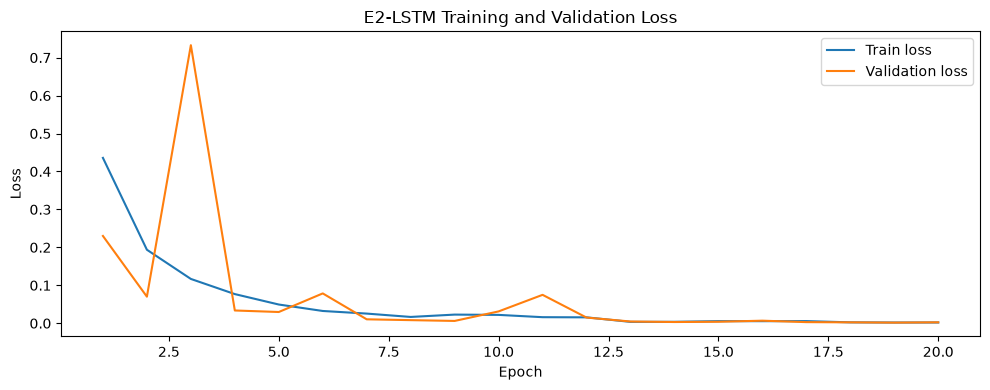

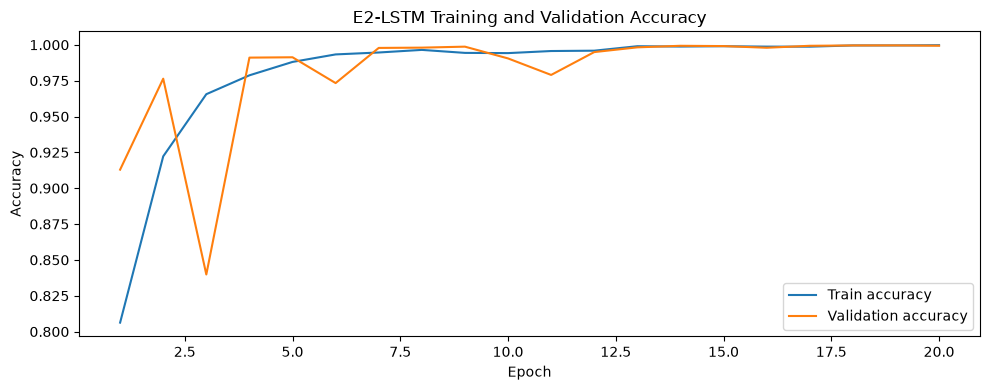

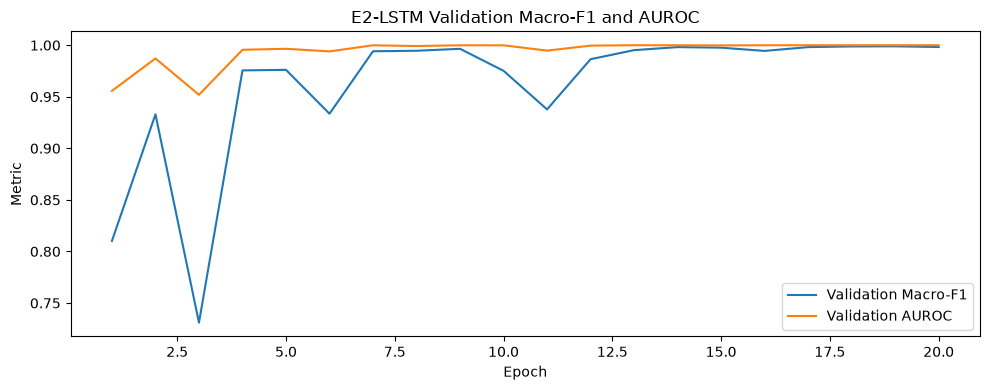

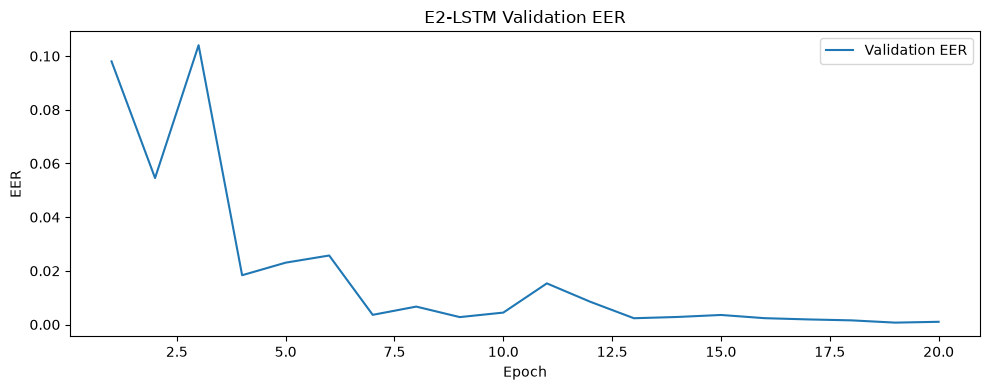

In [20]:
# 18. Plot and save training curves

plt.figure(figsize=(10,4))
plt.plot(history_df["epoch"],history_df["train_loss"],label="Train loss")
plt.plot(history_df["epoch"],history_df["val_loss"],label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("E2-LSTM Training and Validation Loss")
plt.legend()
plt.tight_layout()
loss_fig_path=RESULT_FIGURE_DIR/"E2_LSTM_training_loss_v1.png"
plt.savefig(loss_fig_path,dpi=200)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(history_df["epoch"],history_df["train_accuracy"],label="Train accuracy")
plt.plot(history_df["epoch"],history_df["val_accuracy"],label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("E2-LSTM Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
accuracy_fig_path=RESULT_FIGURE_DIR/"E2_LSTM_training_accuracy_v1.png"
plt.savefig(accuracy_fig_path,dpi=200)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(history_df["epoch"],history_df["val_macro_f1"],label="Validation Macro-F1")
plt.plot(history_df["epoch"],history_df["val_auroc"],label="Validation AUROC")
plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("E2-LSTM Validation Macro-F1 and AUROC")
plt.legend()
plt.tight_layout()
metric_fig_path=RESULT_FIGURE_DIR/"E2_LSTM_validation_metrics_v1.png"
plt.savefig(metric_fig_path,dpi=200)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(history_df["epoch"],history_df["val_eer"],label="Validation EER")
plt.xlabel("Epoch")
plt.ylabel("EER")
plt.title("E2-LSTM Validation EER")
plt.legend()
plt.tight_layout()
eer_fig_path=RESULT_FIGURE_DIR/"E2_LSTM_validation_eer_v1.png"
plt.savefig(eer_fig_path,dpi=200)
plt.show()


# 13. Final development evaluation

After training, we reload the checkpoint with the best development Macro-F1.

All reported development metrics below therefore correspond to the selected E2-LSTM checkpoint rather than simply the final training epoch.


In [21]:
# 19. Load the best E2-LSTM checkpoint before final validation

checkpoint=torch.load(best_checkpoint_path,map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])

print("Loaded checkpoint from epoch:",checkpoint["epoch"])
print("Best validation Macro-F1:",checkpoint["best_val_macro_f1"])

Loaded checkpoint from epoch: 19
Best validation Macro-F1: 0.9989067105686358


## Development-set results

These are the metrics we use to understand how well the clean E2-LSTM baseline learned the bonafide/spoof classification task.

The development predictions are also saved so that later analysis can inspect individual recordings.


In [22]:
# 20. Final development-set evaluation

val_metrics,val_y,val_scores,val_preds,val_ids=run_evaluation(model,dev_loader,criterion)

print("E2-LSTM validation results")
print("-"*30)

for key,value in val_metrics.items():
    print(f"{key:<16}: {value:.6f}")

with open(
    EXPERIMENT_DIR/"E2_LSTM_validation_metrics_v1.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(val_metrics,f,indent=2)


Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

E2-LSTM validation results
------------------------------
macro_f1        : 0.998907
accuracy        : 0.999597
auroc           : 0.999987
eer             : 0.000706
eer_threshold   : 0.944707
loss            : 0.001662


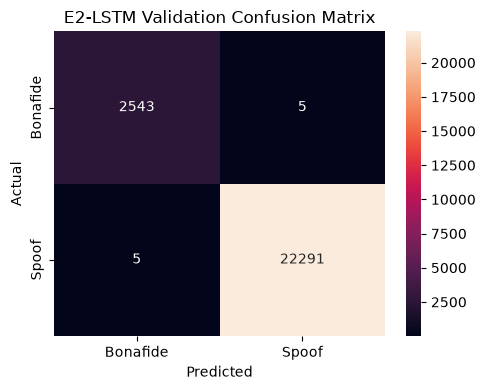

[[ 2543     5]
 [    5 22291]]


In [23]:
# 21. Validation confusion matrix

cm=confusion_matrix(val_y,val_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Bonafide","Spoof"],
    yticklabels=["Bonafide","Spoof"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("E2-LSTM Validation Confusion Matrix")
plt.tight_layout()

cm_path=RESULT_FIGURE_DIR/"E2_LSTM_validation_confusion_matrix_v1.png"
plt.savefig(cm_path,dpi=200)
plt.show()

print(cm)


## Save development predictions

Saving the individual prediction scores is useful later when comparing E2-LSTM with later experiments or investigating difficult examples.

The file contains the model's spoof score, predicted class and ground-truth label for each development recording.


In [24]:
# 22. Save validation predictions for later analysis

val_predictions_df=pd.DataFrame({
    "file_id":val_ids,
    "label":val_y,
    "spoof_score":val_scores,
    "prediction":val_preds
})

val_predictions_path=EXPERIMENT_DIR/"E2_LSTM_dev_predictions_v1.csv"
val_predictions_df.to_csv(
    val_predictions_path,
    index=False
)

print("Saved:",val_predictions_path)


Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E2_LSTM/E2_LSTM_dev_predictions_v1.csv


# 14. Official evaluation inference

The official evaluation partition is processed only after the E2-LSTM checkpoint has been selected using the development set.

If evaluation labels are available, the notebook calculates the same metrics used on the development set.

If labels are not available, it saves prediction scores without inventing evaluation metrics.


In [25]:
# 23. Prepare the official evaluation loader

def build_eval_loader(df):
    if len(df)==0:
        return None

    class EvalWaveformDataset(Dataset):
        def __init__(self,df):
            self.df=df.reset_index(drop=True)

        def __len__(self):
            return len(self.df)

        def __getitem__(self,index):
            row=self.df.iloc[index]
            audio_path=PROJECT_ROOT/Path(row["audio_path"])
            waveform=load_audio(audio_path)
            waveform=fixed_length_audio(
                waveform,
                training=False
            )

            label=-1 if pd.isna(row["label"]) else int(row["label"])
            y=torch.tensor(label,dtype=torch.long)

            return (
                torch.from_numpy(waveform).float(),
                y,
                row["file_id"]
            )

    dataset=EvalWaveformDataset(df)

    kwargs={
        "batch_size":BATCH_SIZE,
        "shuffle":False,
        "num_workers":NUM_WORKERS,
        "pin_memory":DEVICE.type=="cuda",
        "persistent_workers":NUM_WORKERS>0,
        "worker_init_fn":seed_worker,
        "generator":torch.Generator().manual_seed(SEED)
    }

    if NUM_WORKERS>0:
        kwargs["prefetch_factor"]=PREFETCH_FACTOR

    return DataLoader(dataset,**kwargs)


eval_scores=np.asarray([])
eval_labels=np.asarray([])
eval_ids=[]

eval_loader=build_eval_loader(eval_run_df) if len(eval_run_df) else None

print("Evaluation loader ready:",eval_loader is not None)

Evaluation loader ready: True


In [26]:
# 24. Run official evaluation inference

if len(eval_run_df):
    eval_loader=build_eval_loader(eval_run_df)

    model.eval()

    eval_scores=[]
    eval_labels=[]
    eval_ids=[]

    with torch.no_grad():
        for waveforms,y,file_ids in tqdm(
            eval_loader,
            desc="Official evaluation"
        ):
            x=waveform_batch_to_features(waveforms)

            logits=model(x)
            scores=torch.softmax(logits,dim=1)[:,1]

            eval_scores.extend(
                scores.cpu().numpy().tolist()
            )
            eval_labels.extend(
                y.numpy().tolist()
            )
            eval_ids.extend(
                list(file_ids)
            )

    eval_scores=np.asarray(eval_scores)
    eval_labels=np.asarray(eval_labels)

    eval_predictions=(eval_scores>=0.5).astype(int)

    eval_output=pd.DataFrame({
        "file_id":eval_ids,
        "spoof_score":eval_scores,
        "prediction":eval_predictions
    })

    eval_output_path=EXPERIMENT_DIR/"E2_LSTM_eval_predictions_v1.csv"

    eval_output.to_csv(
        eval_output_path,
        index=False
    )

    print("Saved:",eval_output_path)

    # Calculate metrics only when evaluation labels are available
    if np.all(eval_labels>=0):
        eval_metrics,_=calculate_metrics(
            eval_labels,
            eval_scores
        )

        print("\nOfficial evaluation results")
        print("-"*30)

        for key,value in eval_metrics.items():
            print(f"{key:<16}: {value:.6f}")

        with open(
            EXPERIMENT_DIR/"E2_LSTM_eval_metrics_v1.json",
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(eval_metrics,f,indent=2)

    else:
        print(
            "\nEvaluation predictions were saved, "
            "but public evaluation labels were not available."
        )

else:
    print("No evaluation manifest was found.")


Official evaluation:   0%|          | 0/2227 [00:00<?, ?it/s]

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E2_LSTM/E2_LSTM_eval_predictions_v1.csv

Official evaluation results
------------------------------
macro_f1        : 0.760915
accuracy        : 0.864775
auroc           : 0.966625
eer             : 0.068239
eer_threshold   : 0.000204


Generator/system identity analysis
--------------------------------------------------
Train system IDs: ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']
Dev system IDs: ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']
Eval system IDs: ['-', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']

System IDs shared with train:
['-']

System IDs unseen during training:
['A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']

System IDs shared with dev:
['-']

Speaker overlap
--------------------------------------------------
Train ∩ Eval: 0
Dev ∩ Eval: 0

Evaluation confusion matrix
--------------------------------------------------
[[ 7326    29]
 [ 9604 54278]]

Evaluation class-wise metrics
--------------------------------------------------
Bonafide  : F1=0.603335
Spoof     : F1=0.918495

Per-system evaluation results
--------------------------------------------------


,system_id,samples,spoof_detected,spoof_missed,spoof_recall,false_negative_rate,mean_spoof_score
10,A17,4914,101,4813,0.020554,0.979446,0.020655
8,A15,4914,1897,3017,0.386040,0.613960,0.402271
7,A14,4914,4280,634,0.870981,0.129019,0.839897
1,A08,4914,4381,533,0.891534,0.108466,0.890867
4,A11,4914,4665,249,0.949328,0.050672,0.930151
3,A10,4914,4712,202,0.958893,0.041107,0.941457
12,A19,4914,4846,68,0.986162,0.013838,0.985867
11,A18,4914,4879,35,0.992877,0.007123,0.991448
6,A13,4914,4887,27,0.994505,0.005495,0.982898
5,A12,4914,4892,22,0.995523,0.004477,0.986741



Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E2_LSTM/E2_LSTM_eval_system_results_v1.csv


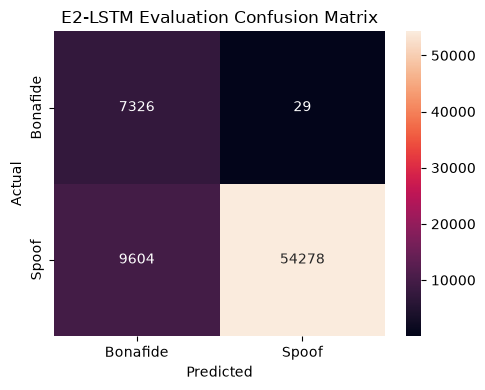

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/ASV_E2_LSTM/E2_LSTM_eval_confusion_matrix_v1.png


In [27]:
# Evaluation generalization analysis

if len(eval_run_df) and len(eval_scores):

    eval_analysis=eval_run_df[
        ["file_id","speaker_id","system_id","key","label"]
    ].copy()

    eval_analysis["spoof_score"]=eval_scores
    eval_analysis["prediction"]=(eval_scores>=0.5).astype(int)

    train_systems=set(train_df["system_id"])
    dev_systems=set(dev_df["system_id"])
    eval_systems=set(eval_df["system_id"])

    train_speakers=set(train_df["speaker_id"])
    dev_speakers=set(dev_df["speaker_id"])
    eval_speakers=set(eval_df["speaker_id"])

    print("Generator/system identity analysis")
    print("-"*50)

    print("Train system IDs:",sorted(train_systems))
    print("Dev system IDs:",sorted(dev_systems))
    print("Eval system IDs:",sorted(eval_systems))

    print("\nSystem IDs shared with train:")
    print(sorted(eval_systems&train_systems))

    print("\nSystem IDs unseen during training:")
    print(sorted(eval_systems-train_systems))

    print("\nSystem IDs shared with dev:")
    print(sorted(eval_systems&dev_systems))

    print("\nSpeaker overlap")
    print("-"*50)

    print("Train ∩ Eval:",len(train_speakers&eval_speakers))
    print("Dev ∩ Eval:",len(dev_speakers&eval_speakers))

    eval_cm=confusion_matrix(
        eval_labels,
        eval_analysis["prediction"].to_numpy()
    )

    print("\nEvaluation confusion matrix")
    print("-"*50)
    print(eval_cm)

    print("\nEvaluation class-wise metrics")
    print("-"*50)

    class_names=["Bonafide","Spoof"]

    for class_index,class_name in enumerate(class_names):

        class_true=(eval_labels==class_index).astype(int)
        class_pred=(
            eval_analysis["prediction"].to_numpy()==class_index
        ).astype(int)

        class_f1=f1_score(
            class_true,
            class_pred
        )

        print(
            f"{class_name:<10}: "
            f"F1={class_f1:.6f}"
        )

    print("\nPer-system evaluation results")
    print("-"*50)

    system_results=[]

    for system_id,group in eval_analysis.groupby("system_id"):

        if system_id=="-":
            continue

        y_true=group["label"].to_numpy()
        predictions=group["prediction"].to_numpy()
        scores=group["spoof_score"].to_numpy()

        spoof_count=(y_true==1).sum()
        detected_spoof=((y_true==1)&(predictions==1)).sum()
        missed_spoof=((y_true==1)&(predictions==0)).sum()

        spoof_recall=(
            detected_spoof/spoof_count
            if spoof_count>0
            else np.nan
        )

        false_negative_rate=(
            missed_spoof/spoof_count
            if spoof_count>0
            else np.nan
        )

        system_results.append({
            "system_id":system_id,
            "samples":len(group),
            "spoof_detected":detected_spoof,
            "spoof_missed":missed_spoof,
            "spoof_recall":spoof_recall,
            "false_negative_rate":false_negative_rate,
            "mean_spoof_score":scores.mean()
        })

    system_results_df=pd.DataFrame(system_results)

    if len(system_results_df):

        system_results_df=system_results_df.sort_values(
            "spoof_recall"
        )

        display(system_results_df)

        system_results_path=(
            EXPERIMENT_DIR/"E2_LSTM_eval_system_results_v1.csv"
        )

        system_results_df.to_csv(
            system_results_path,
            index=False
        )

        print("\nSaved:",system_results_path)

    else:
        print("No spoof system results were found.")

    eval_cm_path=(
        RESULT_FIGURE_DIR/
        "E2_LSTM_eval_confusion_matrix_v1.png"
    )

    plt.figure(figsize=(5,4))

    sns.heatmap(
        eval_cm,
        annot=True,
        fmt="d",
        xticklabels=["Bonafide","Spoof"],
        yticklabels=["Bonafide","Spoof"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("E2-LSTM Evaluation Confusion Matrix")
    plt.tight_layout()
    plt.savefig(eval_cm_path,dpi=200)
    plt.show()

    print("Saved:",eval_cm_path)

else:
    print("Evaluation results are not available.")

## ASVspoof 2019 LA System IDs

The `system_id` field identifies the spoofing/attack system that generated
a spoofed utterance in the ASVspoof 2019 Logical Access (LA) dataset.

The training and development partitions contain systems A01-A06.
The evaluation partition contains A07-A19, with A16 and A19 using the
same core algorithms as A04 and A06 respectively, but generated using
the evaluation-set data.

### Training and Development Systems

| System ID | Type | Description |
|---|---|---|
| A01 | TTS | Neural statistical parametric TTS using a WaveNet neural vocoder. |
| A02 | TTS | Neural TTS similar to A01, but using the WORLD vocoder instead of WaveNet. |
| A03 | TTS | Neural TTS based on the Merlin toolkit, using feed-forward neural networks and the WORLD vocoder. |
| A04 | TTS | Waveform-concatenation TTS based on MaryTTS and diphone unit selection. |
| A05 | VC | VAE-based non-parallel voice conversion using the WORLD vocoder. |
| A06 | VC | Transfer-function-based voice conversion using GMM-UBM modeling and spectral filtering/overlap-add. |

### Evaluation Systems

| System ID | Type | Description |
|---|---|---|
| A07 | TTS | Neural TTS using a WORLD vocoder followed by a WaveCycleGAN2 neural post-filter. |
| A08 | TTS | Neural TTS similar to A01, using a neural source-filter waveform model. |
| A09 | TTS | Neural statistical parametric TTS designed for real-time/mobile use, using LSTM models and the Vocaine vocoder. |
| A10 | TTS | End-to-end Tacotron 2 based TTS with a speaker encoder and WaveRNN vocoder. |
| A11 | TTS | Same general TTS architecture as A10, but uses Griffin-Lim instead of WaveRNN for waveform generation. |
| A12 | TTS | Neural TTS using an autoregressive WaveNet waveform generator. |
| A13 | VC + TTS | Combined TTS and voice-conversion system using VoiceText TTS followed by neural VC and waveform modification. |
| A14 | VC + TTS | Combined TTS and VC system using a commercial TTS engine, ASR bottleneck features, an LSTM acoustic model and STRAIGHT vocoder. |
| A15 | VC + TTS | Similar to A14, but uses speaker-dependent WaveNet vocoders instead of STRAIGHT. |
| A16 | TTS | Waveform-concatenation TTS using the same core algorithm as A04, but constructed using evaluation-set VCTK data. |
| A17 | VC | VAE-based voice conversion similar to A05, but using generalized direct waveform modification instead of the WORLD vocoder. |
| A18 | VC | Non-parallel voice conversion based on an i-vector/PLDA framework with an MFCC-based vocoder. |
| A19 | VC | Transfer-function-based voice conversion using the same core algorithm as A06, but constructed using evaluation-set VCTK data. |

### Important Generalization Groups

For this experiment, the system IDs are especially important because they
help distinguish between familiar and unseen spoofing mechanisms.

- **A01-A06:** spoofing systems present in training/development.
- **A07-A15:** evaluation systems with spoofing mechanisms not directly
  represented by A01-A06.
- **A16:** evaluation system using the same core algorithm as A04.
- **A17-A18:** different voice-conversion systems using mechanisms not
  directly represented by the training systems.
- **A19:** evaluation system using the same core algorithm as A06.

Therefore, evaluation performance on A07-A19 provides a useful test of
generalization beyond the spoofing systems observed during training.

For our E2-LSTM experiment, `system_id="-"` represents bona-fide recordings,
which do not have a spoofing-system identifier.

**Source:** Wang et al., *ASVspoof 2019: A large-scale public database of
synthesized, converted and replayed speech*.

In [28]:
# Evaluation failure-case analysis

if len(eval_analysis):

    false_negatives=eval_analysis[
        (eval_analysis["label"]==1)&
        (eval_analysis["prediction"]==0)
    ].copy()

    false_positives=eval_analysis[
        (eval_analysis["label"]==0)&
        (eval_analysis["prediction"]==1)
    ].copy()

    false_negatives=false_negatives.sort_values(
        "spoof_score"
    )

    false_positives=false_positives.sort_values(
        "spoof_score",
        ascending=False
    )

    print("Evaluation failure-case analysis")
    print("-"*50)

    print(
        "\nFalse-negative spoof samples:",
        len(false_negatives)
    )

    print(
        "False-positive bonafide samples:",
        len(false_positives)
    )

    print("\nMost confidently missed spoof samples")
    print("-"*50)

    display(
        false_negatives[
            [
                "file_id",
                "speaker_id",
                "system_id",
                "spoof_score"
            ]
        ].head(25)
    )

    print("\nMost confidently misclassified bonafide samples")
    print("-"*50)

    display(
        false_positives[
            [
                "file_id",
                "speaker_id",
                "system_id",
                "spoof_score"
            ]
        ].head(25)
    )

    failure_cases=pd.concat(
        [
            false_negatives.head(25).assign(
                error_type="false_negative"
            ),
            false_positives.head(25).assign(
                error_type="false_positive"
            )
        ]
    )

    failure_cases_path=(
        EXPERIMENT_DIR/
        "E2_LSTM_eval_failure_cases_v1.csv"
    )

    failure_cases.to_csv(
        failure_cases_path,
        index=False
    )

    print("\nSaved:",failure_cases_path)

else:
    print("Evaluation analysis is not available.")

Evaluation failure-case analysis
--------------------------------------------------

False-negative spoof samples: 9604
False-positive bonafide samples: 29

Most confidently missed spoof samples
--------------------------------------------------


,file_id,speaker_id,system_id,spoof_score
31298,LA_E_9458286,LA_0020,A17,0.000007
37722,LA_E_1979110,LA_0012,A17,0.000007
48070,LA_E_7078876,LA_0024,A17,0.000007
65445,LA_E_9241968,LA_0019,A17,0.000007
4764,LA_E_3344337,LA_0004,A17,0.000007
18276,LA_E_2912331,LA_0024,A17,0.000007
16657,LA_E_3784228,LA_0022,A17,0.000007
45916,LA_E_6880563,LA_0016,A17,0.000007
39461,LA_E_6405854,LA_0029,A17,0.000007
1720,LA_E_7452185,LA_0018,A17,0.000007



Most confidently misclassified bonafide samples
--------------------------------------------------


,file_id,speaker_id,system_id,spoof_score
36686,LA_E_3462351,LA_0057,-,0.999916
62761,LA_E_1450790,LA_0057,-,0.999900
8979,LA_E_2329497,LA_0048,-,0.999858
44107,LA_E_6372044,LA_0036,-,0.999367
67992,LA_E_4384226,LA_0059,-,0.998419
61662,LA_E_3325942,LA_0059,-,0.994743
50247,LA_E_9688311,LA_0013,-,0.991104
40866,LA_E_7647451,LA_0059,-,0.990538
23641,LA_E_8509707,LA_0059,-,0.987061
2289,LA_E_1244505,LA_0031,-,0.986984



Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E2_LSTM/E2_LSTM_eval_failure_cases_v1.csv


Generator/system identity analysis
--------------------------------------------------
Train system IDs: ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']
Dev system IDs: ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']
Eval system IDs: ['-', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']

System IDs shared with train:
['-']

System IDs unseen during training:
['A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']

System IDs shared with dev:
['-']

Speaker overlap
--------------------------------------------------
Train ∩ Eval: 0
Dev ∩ Eval: 0

Evaluation confusion matrix
--------------------------------------------------
[[ 7326    29]
 [ 9604 54278]]

Evaluation class-wise metrics
--------------------------------------------------
Bonafide  : F1=0.603335
Spoof     : F1=0.918495

Per-system evaluation results
--------------------------------------------------


,system_id,samples,spoof_detected,spoof_missed,spoof_recall,false_negative_rate,mean_spoof_score
10,A17,4914,101,4813,0.020554,0.979446,0.020655
8,A15,4914,1897,3017,0.386040,0.613960,0.402271
7,A14,4914,4280,634,0.870981,0.129019,0.839897
1,A08,4914,4381,533,0.891534,0.108466,0.890867
4,A11,4914,4665,249,0.949328,0.050672,0.930151
3,A10,4914,4712,202,0.958893,0.041107,0.941457
12,A19,4914,4846,68,0.986162,0.013838,0.985867
11,A18,4914,4879,35,0.992877,0.007123,0.991448
6,A13,4914,4887,27,0.994505,0.005495,0.982898
5,A12,4914,4892,22,0.995523,0.004477,0.986741



Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E2_LSTM/E2_LSTM_eval_system_results_v1.csv


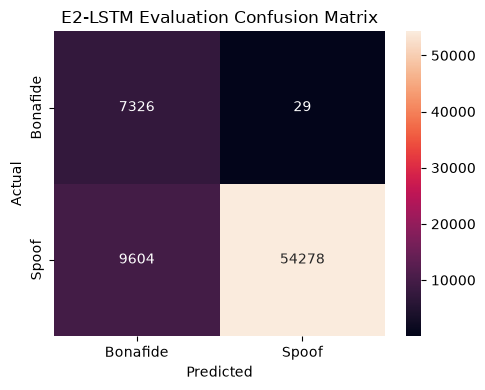

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/ASV_E2_LSTM/E2_LSTM_eval_confusion_matrix_v1.png


In [29]:
# 24.5. Evaluation generalization analysis

if len(eval_run_df) and len(eval_scores):

    eval_analysis=eval_run_df[
        ["file_id","speaker_id","system_id","key","label"]
    ].copy()

    eval_analysis["spoof_score"]=eval_scores
    eval_analysis["prediction"]=(eval_scores>=0.5).astype(int)

    train_systems=set(train_df["system_id"])
    dev_systems=set(dev_df["system_id"])
    eval_systems=set(eval_df["system_id"])

    train_speakers=set(train_df["speaker_id"])
    dev_speakers=set(dev_df["speaker_id"])
    eval_speakers=set(eval_df["speaker_id"])

    print("Generator/system identity analysis")
    print("-"*50)

    print("Train system IDs:",sorted(train_systems))
    print("Dev system IDs:",sorted(dev_systems))
    print("Eval system IDs:",sorted(eval_systems))

    print("\nSystem IDs shared with train:")
    print(sorted(eval_systems&train_systems))

    print("\nSystem IDs unseen during training:")
    print(sorted(eval_systems-train_systems))

    print("\nSystem IDs shared with dev:")
    print(sorted(eval_systems&dev_systems))

    print("\nSpeaker overlap")
    print("-"*50)

    print("Train ∩ Eval:",len(train_speakers&eval_speakers))
    print("Dev ∩ Eval:",len(dev_speakers&eval_speakers))

    eval_cm=confusion_matrix(
        eval_labels,
        eval_analysis["prediction"].to_numpy()
    )

    print("\nEvaluation confusion matrix")
    print("-"*50)
    print(eval_cm)

    print("\nEvaluation class-wise metrics")
    print("-"*50)

    class_names=["Bonafide","Spoof"]

    for class_index,class_name in enumerate(class_names):

        class_true=(eval_labels==class_index).astype(int)
        class_pred=(eval_analysis["prediction"].to_numpy()==class_index).astype(int)

        class_f1=f1_score(
            class_true,
            class_pred
        )

        print(
            f"{class_name:<10}: "
            f"F1={class_f1:.6f}"
        )

    print("\nPer-system evaluation results")
    print("-"*50)

    system_results=[]

    for system_id,group in eval_analysis.groupby("system_id"):

        if system_id=="-":
            continue

        y_true=group["label"].to_numpy()
        predictions=group["prediction"].to_numpy()
        scores=group["spoof_score"].to_numpy()

        spoof_count=(y_true==1).sum()
        detected_spoof=((y_true==1)&(predictions==1)).sum()
        missed_spoof=((y_true==1)&(predictions==0)).sum()

        spoof_recall=(
            detected_spoof/spoof_count
            if spoof_count>0
            else np.nan
        )

        false_negative_rate=(
            missed_spoof/spoof_count
            if spoof_count>0
            else np.nan
        )

        system_results.append({
            "system_id":system_id,
            "samples":len(group),
            "spoof_detected":detected_spoof,
            "spoof_missed":missed_spoof,
            "spoof_recall":spoof_recall,
            "false_negative_rate":false_negative_rate,
            "mean_spoof_score":scores.mean()
        })

    system_results_df=pd.DataFrame(system_results)

    if len(system_results_df):

        system_results_df=system_results_df.sort_values(
            "spoof_recall"
        )

        display(system_results_df)

        system_results_path=(
            EXPERIMENT_DIR/"E2_LSTM_eval_system_results_v1.csv"
        )

        system_results_df.to_csv(
            system_results_path,
            index=False
        )

        print("\nSaved:",system_results_path)

    else:
        print("No spoof system results were found.")

    eval_cm_path=(
        RESULT_FIGURE_DIR/
        "E2_LSTM_eval_confusion_matrix_v1.png"
    )

    plt.figure(figsize=(5,4))

    sns.heatmap(
        eval_cm,
        annot=True,
        fmt="d",
        xticklabels=["Bonafide","Spoof"],
        yticklabels=["Bonafide","Spoof"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("E2-LSTM Evaluation Confusion Matrix")
    plt.tight_layout()
    plt.savefig(eval_cm_path,dpi=200)
    plt.show()

    print("Saved:",eval_cm_path)

else:
    print("Evaluation results are not available.")

# 15. E1 vs E2 controlled baseline comparison
When E1 validation metrics are available, this optional cell compares the clean E1 reference against E2-LSTM. The comparison uses the same ASVspoof partitions and input representation; the intended research change is the temporal LSTM head.

In [30]:
# E1 vs E2 controlled development comparison

e1_candidates=[
    PROJECT_ROOT/"experiments"/"baselines"/"E1"/"validation_metrics_v1.json",
    PROJECT_ROOT/"experiments"/"baselines"/"E1"/"E1_validation_metrics_v1.json"
]

e1_path=next((p for p in e1_candidates if p.exists()),None)
e2_path=EXPERIMENT_DIR/"E2_LSTM_validation_metrics_v1.json"

if e1_path is not None and e2_path.exists():
    with e1_path.open("r",encoding="utf-8") as f:
        e1_metrics=json.load(f)

    with e2_path.open("r",encoding="utf-8") as f:
        e2_metrics=json.load(f)

    comparison_df=pd.DataFrame([
        {
            "model":"E1 MobileNetV3-Small",
            "macro_f1":e1_metrics.get("macro_f1",np.nan),
            "accuracy":e1_metrics.get("accuracy",np.nan),
            "auroc":e1_metrics.get("auroc",np.nan),
            "eer":e1_metrics.get("eer",np.nan)
        },
        {
            "model":"E2 MobileNetV3-Small + LSTM",
            "macro_f1":e2_metrics.get("macro_f1",np.nan),
            "accuracy":e2_metrics.get("accuracy",np.nan),
            "auroc":e2_metrics.get("auroc",np.nan),
            "eer":e2_metrics.get("eer",np.nan)
        }
    ])

    display(comparison_df)

    comparison_path=EXPERIMENT_DIR/"E1_vs_E2_dev_comparison_v1.csv"
    comparison_df.to_csv(comparison_path,index=False)
    print("Saved:",comparison_path)
else:
    print("E1 validation metrics are not available yet; skipping comparison.")


,model,macro_f1,accuracy,auroc,eer
0,E1 MobileNetV3-Small,0.997919,0.999235,0.999891,0.002058
1,E2 MobileNetV3-Small + LSTM,0.998907,0.999597,0.999987,0.000706


Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E2_LSTM/E1_vs_E2_dev_comparison_v1.csv


# 16. Save the E2 experiment configuration

The final configuration records the model, preprocessing, dataset preparation version and training settings.

This is important because later changes to preprocessing or model design should produce a new experiment version rather than silently changing the meaning of E1.


In [32]:
# 25. Save the complete E2-LSTM configuration

config={
    "experiment":"E2-LSTM",
    "experiment_version":EXPERIMENT_VERSION,
    "input_preprocessing_version":INPUT_PREPROCESSING_VERSION,
    "dataset_preparation_version":"v1.0",

    "model":{
        "name":"MobileNetV3-Small-LSTM",
        "backbone":"MobileNetV3-Small",
        "temporal_model":"LSTM",
        "lstm_hidden_size":LSTM_HIDDEN_SIZE,
        "lstm_layers":LSTM_LAYERS,
        "classifier_dropout":CLASSIFIER_DROPOUT,
        "weights":"scratch",
        "input_channels":1,
        "num_classes":2,
        "total_parameters":total_params,
        "trainable_parameters":trainable_params
    },

    "dataset":{
        "name":"ASVspoof 2019 Logical Access",
        "train_manifest":"data/manifests/ASVSpoof/train_manifest.csv",
        "dev_manifest":"data/manifests/ASVSpoof/dev_manifest.csv",
        "eval_manifest":"data/manifests/ASVSpoof/eval_manifest.csv",
        "train_samples":len(train_run_df),
        "dev_samples":len(dev_run_df),
        "eval_samples":len(eval_run_df)
    },

    "audio":{
        "sample_rate":SAMPLE_RATE,
        "segment_seconds":SEGMENT_SECONDS,
        "num_samples":NUM_SAMPLES
    },

    "spectrogram":{
        "n_fft":N_FFT,
        "win_length":WIN_LENGTH,
        "hop_length":HOP_LENGTH,
        "n_mels":N_MELS,
        "window":"hann",
        "power":2.0,
        "log_epsilon":LOG_EPS
    },

    "training_preprocessing":{
        "train_crop":"random",
        "eval_crop":"center",
        "short_audio":"zero_pad",
        "normalization":"training_set_mean_std",
        "feature_pipeline":"batched_gpu_logmel"
    },

    "training":{
        "seed":SEED,
        "batch_size":BATCH_SIZE,
        "epochs":EPOCHS,
        "learning_rate":LEARNING_RATE,
        "weight_decay":WEIGHT_DECAY,
        "patience":PATIENCE,
        "loss":"class_weighted_cross_entropy",
        "optimizer":"AdamW",
        "num_workers":NUM_WORKERS,
        "prefetch_factor":PREFETCH_FACTOR,
        "cudnn_deterministic":(
            torch.backends.cudnn.deterministic
            if DEVICE.type=="cuda"
            else None
        ),
        "cudnn_benchmark":(
            torch.backends.cudnn.benchmark
            if DEVICE.type=="cuda"
            else None
        )
    },

    "excluded_from_E2":[
        "environmental_noise",
        "codec_simulation",
        "telephony_filtering",
        "SpecAugment",
        "robustness_consistency_loss",
        "knowledge_distillation",
        "pruning",
        "quantization",
        "edge_benchmarking"
    ]
}

config_path=EXPERIMENT_DIR/"E2_LSTM_config_v1.json"

with config_path.open("w",encoding="utf-8") as f:
    json.dump(config,f,indent=2)

print("Saved configuration:",config_path)

Saved configuration: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E2_LSTM/E2_LSTM_config_v1.json


# E2 Final Observations

## Model

E2 uses a MobileNetV3-Small convolutional feature extractor followed by frequency-only pooling, a 1-layer LSTM and a binary classifier.

## Dataset

The frozen ASVspoof 2019 Logical Access train/dev/eval manifests are used without changing the prepared split assignments.

## Input pipeline

E2 uses the same 16 kHz, 4-second, 80-bin log-Mel preprocessing as E1, including random training crops, center evaluation crops and zero-padding for short recordings. The implementation computes Log-Mel features in batches on the GPU rather than inside each dataset sample.

## Temporal modeling

E1 classifies after MobileNet's global pooling. E2 preserves the feature-map time axis and feeds the sequence into the LSTM.

## Generalization

The official evaluation partition is used only after checkpoint selection. Per-system and speaker overlap analysis is retained to inspect unseen-system generalization.

## Experimental boundary

E2 does not include codec simulation, environmental noise, robustness consistency loss, pruning, quantization or edge benchmarking.

# 17. E2 outputs and experiment record

After a successful run, E2-LSTM should leave behind four kinds of evidence:

1. **Configuration** - exactly how E2-LSTM was run.
2. **Checkpoint** - the selected MobileNetV3-Small + LSTM model.
3. **Quantitative results** - Macro-F1, AUROC, EER and related metrics.
4. **Analysis artifacts** - predictions, training curves and confusion matrix.

These artifacts allow E2-LSTM to be compared directly with the E1 reference baseline.


In [33]:
# E2-LSTM experiment artifact audit

required_artifacts={
    "Best checkpoint":
        CHECKPOINT_DIR/"E2_MobileNetV3Small_LSTM_v1_best.pt",

    "Validation metrics":
        EXPERIMENT_DIR/"E2_LSTM_validation_metrics_v1.json",

    "Training history":
        EXPERIMENT_DIR/"training_history.csv",

    "Log-Mel normalization statistics":
        EXPERIMENT_DIR/"logmel_stats.json",

    "System generalization results":
        EXPERIMENT_DIR/"E2_LSTM_eval_system_results_v1.csv",

    "Failure-case results":
        EXPERIMENT_DIR/"E2_LSTM_eval_failure_cases_v1.csv",

    "Evaluation confusion matrix":
        RESULT_FIGURE_DIR/"E2_LSTM_eval_confusion_matrix_v1.png",

    "Validation loss figure":
        RESULT_FIGURE_DIR/"E2_LSTM_training_loss_v1.png",

    "Validation metrics figure":
        RESULT_FIGURE_DIR/"E2_LSTM_validation_metrics_v1.png",

    "Validation EER figure":
        RESULT_FIGURE_DIR/"E2_LSTM_validation_eer_v1.png"
}

print("E2-LSTM experiment artifact audit")
print("-"*50)

all_available=True

for name,path in required_artifacts.items():

    status="OK" if path.exists() else "MISSING"

    print(f"{name:<35}: {status}")

    if not path.exists():
        all_available=False

print("-"*50)

if all_available:
    print("All required E2-LSTM artifacts are available.")
else:
    print("Some E2-LSTM artifacts are missing. Check the paths above.")

E2-LSTM experiment artifact audit
--------------------------------------------------
Best checkpoint                    : OK
Validation metrics                 : OK
Training history                   : OK
Log-Mel normalization statistics   : OK
System generalization results      : OK
Failure-case results               : OK
Evaluation confusion matrix        : OK
Validation loss figure             : OK
Validation metrics figure          : OK
Validation EER figure              : OK
--------------------------------------------------
All required E2-LSTM artifacts are available.
